---
title: "L7-06 · Sample complexity and resource accounting"
short_title: "Sample complexity and resource accounting"
subtitle: "A speedup is a statement about one resource under one access model; Hoeffding gives reproducible shot counts for fixed designs, and counting data loading, depth and noise can turn a quadratic or Heisenberg-type gain into nothing or into a constant factor."
description: "Separate copies, queries, gates, depth, shots and classical cost; derive Hoeffding sample sizes with proof; and test whether a claimed quantum advantage survives once every resource is counted under a stated access model."
tags: [level-7, coursebook]
---

(lesson-l7-06)=

:::{div}
:class: qcai-meta
![Level 7 icon](../../_static/icons/qicon-level-7.svg) **Level 7 · Doctoral & postdoctoral** · about 125 minutes  
**Big idea.** A speedup is a statement about one resource under one access model; Hoeffding gives reproducible shot counts for fixed designs, and counting data loading, depth and noise can turn a quadratic or Heisenberg-type gain into nothing or into a constant factor.  
**Before this lesson.** [L7-04](#lesson-l7-04), [L7-05](#lesson-l7-05)  
**Lab.** [Chance and repeated trials](../../labs/01-chance.ipynb)
:::

## What you will be able to do

- Prove Hoeffding's inequality from Hoeffding's lemma and compute $N \ge (2/\varepsilon^2)\ln(2/\delta)$ for one or many bounded means, stating the independence and fixed-design assumptions.
- Classify the resources of a quantum procedure as copies, oracle queries, gates, depth, shots or classical processing, and say which comparison a claimed advantage concerns.
- Show with Grover search that a query advantage survives for a computable oracle and vanishes for an unstructured classical table.
- Derive the optimal number of coherent queries per shot under dephasing and explain why it gives a constant-factor gain instead of Heisenberg scaling.

## Why this matters

Grover's algorithm finds a marked item among $N = 2^{20} = 1{,}048{,}576$ with 804 oracle queries, against $N - 1 = 1{,}048{,}575$ in the worst case for a classical search. Is that a million-to-804 advantage? It depends on what an oracle query costs and where the items live. If they sit in an unsorted classical table, merely building the oracle reads all $N$ entries, and the advantage is gone.

Every quantum learning or causal-inference claim has the same structure: a count of one resource, under one access model, compared with a classical baseline. This lesson builds the tools to audit such claims: a precise list of resources, concentration bounds that turn accuracy into shot counts, and two worked audits in which an impressive scaling gain disappears or shrinks to a constant once data loading, depth and noise are counted [@nielsenchuang; @advantage].

:::{dropdown} Key terms

**Sample (copy) complexity**
: The number of copies of an unknown state or of independent observations needed to reach accuracy $\varepsilon$ with failure probability at most $\delta$.

**Query complexity**
: The number of calls to an oracle (a black-box unitary or function), counting each call as one unit regardless of how it is implemented.

**Gate count and depth**
: The number of elementary gates in a circuit, and the number of sequential layers; depth controls how long coherence must last.

**Access model**
: The rules for how the algorithm reaches the data or the process: a computable function, a classical table, a quantum memory, copies of a state, or uses of a channel.

**Fisher information**
: For a parametric family of outcome distributions, $F(\varphi) = \sum_x (\partial_\varphi p_x)^2/p_x$; by the Cramer-Rao inequality an unbiased estimator has variance at least $1/F$.

:::


In [1]:
import sys, pathlib, subprocess
here = pathlib.Path.cwd()
root = next((p for p in [here, *here.parents] if (p / "qcai").is_dir()), None)
if root is None:  # for example on Google Colab: fetch the course's small teaching package
    root = pathlib.Path("quantum-causal-ai")
    if not root.exists():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/pozapas/quantum-causal-ai.git", str(root)], check=True)
    root = root.resolve()
sys.path.insert(0, str(root))
from qcai.viz import show as _show, show_mpl as _show_mpl
from qcai.lessonfigs import l7_06 as _lessonfigs

## Six resources that do not substitute for each other

:::{prf:definition} Resources of a quantum procedure
:label: def-l7-06-resources
For a task with accuracy $\varepsilon$ and failure probability $\delta$:

- **copies**: how many times an unknown state is prepared and consumed;
- **queries**: how many times an oracle or unknown process is applied, sequentially or in parallel;
- **gates** and **depth**: elementary operations, and sequential layers of them;
- **shots**: repetitions of a circuit followed by measurement (with single-copy measurements, shots equal copies);
- **classical processing**: pre- and post-processing, including loading data and computing estimators;
- **wall-clock time**: everything above, plus reset, calibration and communication.
:::

```{mermaid}
graph LR
  T[Task: eps, delta] --> C[Copies of a state]
  T --> Q[Oracle queries]
  T --> G[Gates and depth]
  T --> S[Shots]
  T --> P[Classical processing]
  A[Access model] --> Q
  A --> P
  C --> W[Wall-clock cost]
  Q --> W
  G --> W
  S --> W
  P --> W
```

*A task fixes the accuracy and failure probability; the access model decides what one query costs and what must be loaded. Wall-clock cost depends on all of the resources.*

:::{important} Name the resource and the access model
"Exponential speedup" is not a sentence until it says: speedup in which resource, against which classical baseline, under which access model. Huang et al. show, for example, that classical learners given training data can match quantum models on some tasks where computing the quantum model alone is hard, so the comparison must count the data on both sides [@advantage].
:::

## Concentration: how many shots for one mean

:::{prf:lemma} Hoeffding's lemma
:label: lem-l7-06-hl
If $a \le X \le b$ and $\mathbb{E}X = \mu$, then $\mathbb{E}\,e^{s(X - \mu)} \le e^{s^2(b-a)^2/8}$ for every real $s$ [@hoeffding1963].
:::

:::{prf:proof}
By convexity of $e^{sx}$ on $[a, b]$, $e^{sX} \le \frac{b - X}{b - a}e^{sa} + \frac{X - a}{b - a}e^{sb}$. Take expectations and write $p = (\mu - a)/(b - a)$, $u = s(b - a)$: $\mathbb{E}\,e^{s(X-\mu)} \le e^{\phi(u)}$ with $\phi(u) = -pu + \ln(1 - p + pe^u)$. Then $\phi(0) = 0$, $\phi'(0) = 0$, and $\phi''(u) = q(1 - q)$ with $q = pe^u/(1 - p + pe^u) \in [0, 1]$, so $\phi'' \le 1/4$. Taylor's theorem gives $\phi(u) \le u^2/8 = s^2(b-a)^2/8$.
:::

:::{prf:theorem} Hoeffding's inequality
:label: thm-l7-06-hoeff
Let $X_1, \dots, X_N$ be independent with $a \le X_i \le b$ and common mean $\mu$, and $\bar X_N = \frac1N\sum_i X_i$. For every $\varepsilon > 0$,

$$\Pr\big[\bar X_N - \mu \ge \varepsilon\big] \le e^{-2N\varepsilon^2/(b-a)^2}, \qquad \Pr\big[|\bar X_N - \mu| \ge \varepsilon\big] \le 2e^{-2N\varepsilon^2/(b-a)^2}.$$

For outcomes in $[-1, 1]$ the two-sided bound is $2e^{-N\varepsilon^2/2}$ [@hoeffding1963].
:::

:::{prf:proof}
For $s > 0$, Markov's inequality applied to $e^{s(S_N - N\mu)}$ with $S_N = \sum_i X_i$ gives $\Pr[S_N - N\mu \ge N\varepsilon] \le e^{-sN\varepsilon}\,\mathbb{E}\,e^{s(S_N - N\mu)}$ (the Chernoff method [@coverthomas]). Independence factorizes the expectation into $\prod_i \mathbb{E}\,e^{s(X_i - \mu)}$, and Lemma [](#lem-l7-06-hl) bounds it by $e^{Ns^2(b-a)^2/8}$. The exponent $-sN\varepsilon + Ns^2(b-a)^2/8$ is smallest at $s = 4\varepsilon/(b-a)^2$, where it equals $-2N\varepsilon^2/(b-a)^2$. Apply the same argument to $-X_i$ and add the two tails.
:::

:::{figure} ../../_static/animations/l7_06_derivation.mp4
:alt: A probability bound transformed step by step from Markov's inequality to an exponential bound, then solved for the sample size 738.
:width: 100%

Markov, independence, Hoeffding's lemma, then the best $s$: the tail is at most $2e^{-N\varepsilon^2/2}$ for outcomes in $[-1, 1]$, and $\varepsilon = 0.1$, $\delta = 0.05$ need $N = 738$.
:::

:::{dropdown} What the animation shows
The inequality $\Pr[S_N - N\mu \ge N\varepsilon] \le e^{-sN\varepsilon}\mathbb{E}e^{s(S_N - N\mu)}$ is written, labeled as Markov's inequality applied to an exponential. Its right side transforms term by term: independence turns the expectation into a product over $i$; Hoeffding's lemma bounds the product by $e^{Ns^2(b-a)^2/8}$; choosing $s = 4\varepsilon/(b-a)^2$ leaves $e^{-2N\varepsilon^2/(b-a)^2}$. For $[a, b] = [-1, 1]$ and two tails, the bound is $2e^{-N\varepsilon^2/2}$. Setting it at most $\delta$ gives $N \ge (2/\varepsilon^2)\ln(2/\delta)$, and for $\varepsilon = 0.1$, $\delta = 0.05$: $N \ge 200\ln 40 \approx 737.8$, so $N = 738$.
:::

:::{prf:corollary} Sample size for one or many means
:label: cor-l7-06-n
For outcomes in $[-1, 1]$, $N \ge \frac{2}{\varepsilon^2}\ln\frac{2}{\delta}$ shots give $|\bar X_N - \mu| < \varepsilon$ with probability at least $1 - \delta$. For $M$ means estimated from independent samples of size $N$ each, the union bound gives all $M$ within $\varepsilon$ with probability at least $1 - \delta$ when $N \ge \frac{2}{\varepsilon^2}\ln\frac{2M}{\delta}$. With $\varepsilon = 0.1$, $\delta = 0.05$: $N = 738$ for one mean and $1659$ per mean for $M = 100$.
:::

:::{figure} ../../_static/animations/l7_06_band.mp4
:alt: Clouds of 200 sample means at increasing sample sizes, inside a violet Hoeffding band and a wider amber Chebyshev band; then running-mean paths, some of which cross the band.
:width: 100%

At each fixed $N$, almost all of 200 independent means lie inside the Hoeffding band. Running means are different: 11 percent of 400 paths leave the band somewhere, more than $\delta = 5$ percent.
:::

:::{dropdown} What the animation shows
The horizontal axis is the sample size $N$ on a log scale from 10 to 10,000; the vertical axis is the error $\bar X_N - \mu$ for $\pm1$ outcomes with mean $0.2$. A violet band $\pm\sqrt{2\ln(2/\delta)/N}$ and a wider amber band $\pm\sqrt{1/(\delta N)}$ are drawn for $\delta = 0.05$. At $N = 30, 100, 300, 1000, 3000$ and $10{,}000$ a vertical cloud of 200 independent sample means appears, and a counter reports how many fall outside the Hoeffding band, at most a few each time. A dashed line marks $N = 738$, where the band half-width is $0.1$; the Chebyshev bound would need 2000. The clouds are then replaced by 24 running-mean paths, each adding one sample at a time; the red ones cross the band at some $N$. A note states that 11 percent of 400 such paths leave the band somewhere, more than $\delta$, because a guarantee for a fixed $N$ does not cover peeking at every $N$.
:::

:::{prf:remark} Chebyshev, the normal approximation, and what Hoeffding assumes
Chebyshev's inequality needs only a variance bound and gives $N \ge 1/(\delta\varepsilon^2) = 2000$, worse in its $1/\delta$ dependence than Hoeffding's $\ln(2/\delta)$. The normal approximation with variance at most 1, $N \approx z_{1-\delta/2}^2/\varepsilon^2 = 385$, is smaller but is not a bound for finite $N$. Hoeffding's guarantee assumes independent, bounded outcomes and a sample size fixed in advance. Drift in the device breaks independence, and choosing $N$ after looking at the data (optional stopping) breaks the fixed design, as the animation shows; sequential designs need time-uniform bounds instead.
:::


In [2]:
_show(_lessonfigs.sample_size_explorer())

**Explore.** Choose the failure probability $\delta$. Curves give the samples needed for accuracy $\varepsilon$ by Hoeffding, by Chebyshev, by the normal approximation (not a bound), and by Hoeffding for 100 means at once.

:::{dropdown} What the figure shows
A log-log plot of the required number of samples $N$ against the accuracy $\varepsilon$ from 0.005 to 0.5 for outcomes in $[-1, 1]$. All curves fall as $1/\varepsilon^2$. At $\delta = 0.05$ and $\varepsilon = 0.1$ the values are 738 (Hoeffding), 2000 (Chebyshev), 385 (normal approximation) and 1659 per mean for 100 simultaneous means. Moving the slider to $\delta = 10^{-6}$ raises the Hoeffding curve only by the factor $\ln(2\times10^6)/\ln 40 \approx 3.9$, while the Chebyshev curve rises by a factor of 50,000 and passes far above the others.
:::

:::{prf:proposition} Shadow estimates of a Pauli string
:label: prop-l7-06-shadow
Measure every qubit in a uniformly random Pauli basis. For a Pauli string $P$ of weight $k$, the single-snapshot estimate $\hat X = \prod_{j \in \mathrm{supp}P} 3\,b_j\,\mathbf{1}[\text{basis}_j = P_j]$ (with outcomes $b_j = \pm1$) satisfies $\mathbb{E}\hat X = \operatorname{Tr}(\rho P)$ and $\mathbb{E}\hat X^2 = 3^k$.
:::

:::{prf:proof}
Sketch: the bases match $P$ on its support with probability $3^{-k}$, and then $\hat X = 3^k\prod_j b_j$ with conditional mean $\operatorname{Tr}(\rho P)$; otherwise $\hat X = 0$. So $\mathbb{E}\hat X = \operatorname{Tr}(\rho P)$ and $\mathbb{E}\hat X^2 = 3^{-k}\cdot 9^k = 3^k$. The inverse channel behind this estimator, the full proof and the Huang-Kueng-Preskill guarantee are developed in [L7-07](#lesson-l7-07) [@shadows].
:::

:::{prf:remark} What the range-based bound says about shadows
Since $\hat X \in [-3^k, 3^k]$, Hoeffding needs $N \ge 2\cdot9^k\ln(2M/\delta)/\varepsilon^2$ snapshots for $M$ such strings at once; measuring each string directly costs $M\cdot 2\ln(2M/\delta)/\varepsilon^2$ shots in total. With these bounds shadows win when $M > 9^k$. Median-of-means estimators, as used by Huang, Kueng and Preskill, replace the range factor $9^k$ by the variance $3^k$ at the price of larger constants ([L7-07](#lesson-l7-07)). Either way the saving depends on the observables, not only on their number.
:::

## Queries, gates and data access: auditing Grover

:::{prf:proposition} Grover success probability
:label: prop-l7-06-grover
With one marked item among $N$ and $\sin\theta = 1/\sqrt N$, after $k$ Grover iterations (each one oracle query) the probability of measuring the marked item is $\sin^2\big((2k + 1)\theta\big)$. Taking $k = \lfloor \pi/(4\theta) \rfloor$ gives success probability at least $1 - 1/N$; for $N = 2^{20}$ this is $k = 804$ [@grover1996].
:::

:::{prf:proof}
The state stays in the plane spanned by the marked state $|w\rangle$ and the uniform superposition of the others, $|r\rangle$. The start is $\sin\theta|w\rangle + \cos\theta|r\rangle$. The oracle reflects about $|r\rangle$ and the diffusion step reflects about the start; two reflections make a rotation by $2\theta$, so after $k$ iterations the angle from $|r\rangle$ is $(2k+1)\theta$ [@nielsenchuang]. With $k = \lfloor\pi/(4\theta)\rfloor$ the final angle is within $\theta$ of $\pi/2$, so the failure probability is at most $\sin^2\theta = 1/N$. For $N = 2^{20}$, $\pi/(4\theta) \approx 804.2$.
:::

Grover's query count is optimal up to a constant factor: any quantum algorithm needs order $\sqrt N$ queries to an unstructured oracle [@bbbv1997; @nielsenchuang]. A deterministic classical search needs $N - 1 = 1{,}048{,}575$ queries in the worst case, and a randomized one about $N/2$ on average. The gap in queries is real. Whether it is a gap in cost depends on the access model.

:::{figure} ../../_static/animations/l7_06_ledger.mp4
:alt: Two bars on a log scale, classical at about one million queries and quantum at 804; under a classical-table access model the quantum bar grows past the classical one.
:width: 100%

Grover on $2^{20}$ items: 804 queries against 1,048,575. If the oracle is a circuit for a computable predicate the gap survives; if the items are in a classical table, loading them costs $N$ and the advantage vanishes.
:::

:::{dropdown} What the animation shows
The task is to find one marked item among $N = 2^{20} = 1{,}048{,}576$. A log-scale bar chart shows the classical worst-case count $N - 1 = 1{,}048{,}575$ and the Grover count $\lfloor\pi/(4\theta)\rfloor = 804$ with $\sin\theta = 2^{-10}$. Access model A is stated: the predicate $f$ is a circuit we can run, so both costs scale as queries times the cost $c_f$ of one evaluation plus a few gates, and the quadratic gap survives. Access model B follows: the items sit in a classical table, and building the oracle reads all $N$ entries. The quantum bar grows to $804 + 1{,}048{,}576 = 1{,}049{,}380$, above the classical bar. The closing line: same task and algorithm, but the access model decides the advantage.
:::


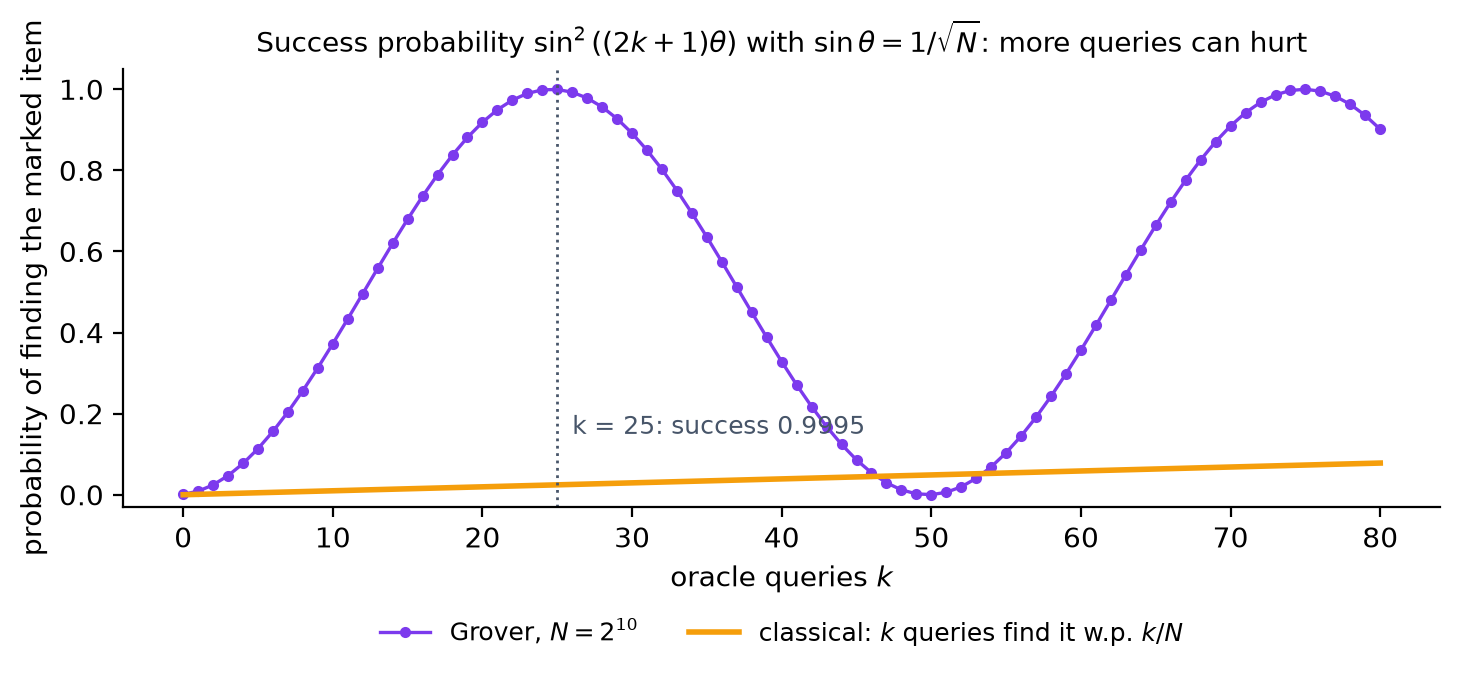

In [3]:
_show_mpl(_lessonfigs.grover_success())

*For $N = 2^{10}$ the success probability peaks at $k = 25$ queries and then falls: queries are not a monotone resource. The classical curve $k/N$ is the chance that $k$ random distinct queries include the marked item.*

:::{warning} Loading cost and quantum memory
Any procedure that builds an oracle from an unstructured classical table of $N$ entries must read every entry at least once, because an entry it never reads cannot affect the oracle. A quantum random-access memory could amortize that cost over many searches of the same table, but it is hardware with order $N$ components, and its preparation, error rates and depth then enter the ledger.
:::

## Queries versus depth: phase estimation under dephasing

To learn a phase $\varphi$ from a unitary $e^{-i\varphi Z/2}$, each shot applies it $k$ times in sequence to $|+\rangle$ and measures $X$; outcome $0$ is the $+1$ eigenvalue of $X$. With dephasing that shrinks coherence by $e^{-\gamma}$ per query, the outcome probability is

$$
P(0 \mid \varphi) = \tfrac12\big(1 + V\cos k\varphi\big), \qquad V = e^{-\gamma k}.
$$ (eq-l7-06-pk)

:::{prf:proposition} Fisher information per shot
:label: prop-l7-06-fisher
For [](#eq-l7-06-pk), $F_{\text{shot}}(\varphi) = \dfrac{k^2V^2\sin^2 k\varphi}{1 - V^2\cos^2 k\varphi} \le k^2V^2 = k^2e^{-2\gamma k}$, with equality where $\cos k\varphi = 0$.
:::

:::{prf:proof}
For two outcomes, $F = (\partial_\varphi P)^2/(P(1-P))$. Here $\partial_\varphi P = -\tfrac12 kV\sin k\varphi$ and $P(1 - P) = \tfrac14(1 - V^2\cos^2 k\varphi)$. Since $V \le 1$, $1 - V^2\cos^2 \ge 1 - \cos^2 = \sin^2$, so the ratio is at most $k^2V^2$, with equality when $\cos k\varphi = 0$.
:::

:::{prf:corollary} The best depth under a fixed query budget
:label: cor-l7-06-opt
With $Q$ queries in total and $Q/k$ independent shots, Fisher information adds: $F_{\text{tot}} \le Qk\,e^{-2\gamma k}$. This is largest at $k^\star = \frac{1}{2\gamma}$, where $F_{\max} = \frac{Q}{2e\gamma}$. By the Cramer-Rao inequality, any unbiased estimator then has $\delta\varphi \ge \sqrt{2e\gamma/Q}$ [@coverthomas]. Without dephasing, $F_{\text{tot}} = Qk$ grows with $k$; a single shot with $k = Q$ reaches $Q^2$, the Heisenberg scaling $\delta\varphi \sim 1/Q$.
:::

:::{figure} ../../_static/animations/l7_06_heisenberg.mp4
:alt: Curves of Fisher information per query against queries per shot, rising then falling, with a red dot at the peak that moves right as the dephasing rate decreases.
:width: 100%

Fisher information per query $k e^{-2\gamma k}$: it follows the noiseless line $k$ only until $k^\star = \frac{1}{2\gamma}$. The best total is $\frac{Q}{2e\gamma}$: a constant-factor gain over repetition, not Heisenberg scaling.
:::

:::{dropdown} What the animation shows
The model $P(0 \mid \varphi) = \frac12(1 + e^{-\gamma k}\cos k\varphi)$ and the bound $F_{\text{shot}} \le k^2e^{-2\gamma k}$ are written. A log-log plot shows Fisher information per query against queries per shot $k$ from 1 to about 5000. A gray line is the noiseless value $k$. A violet curve $ke^{-2\gamma k}$ follows it for small $k$, peaks, and falls; a red dot marks the peak at $k^\star = 1/(2\gamma)$ with height $1/(2e\gamma)$. As $\gamma$ decreases from 0.1 to 0.001, the peak moves from $k = 5$ (height about 1.8) to $k = 500$ (height about 184); it settles at $\gamma = 0.01$ with $k^\star = 50$ and $F/Q \approx 18.4$. The derivation $F_{\text{tot}} = (Q/k)k^2e^{-2\gamma k} = Qke^{-2\gamma k}$, $k^\star = 1/(2\gamma)$, $F_{\max} = Q/(2e\gamma)$ and $\delta\varphi \ge \sqrt{2e\gamma/Q}$ follows, with the remark that the error still scales as $1/\sqrt Q$.
:::


In [4]:
_show(_lessonfigs.fisher_explorer())

**Explore.** Change the dephasing per query $\gamma$. The red marker is the optimal number of sequential queries per shot and the information per query it achieves.

:::{dropdown} What the figure shows
A log-log plot of Fisher information per query against queries per shot $k$ from 1 to 5000. The dashed gray line $F/Q = k$ is the noiseless case. The violet curve is $ke^{-2\gamma k}$ for the chosen $\gamma$ and the red marker its maximum at $k = 1/(2\gamma)$, height $1/(2e\gamma)$. At $\gamma = 0.1$ the marker is at $k = 5$, height $1.84$; at $\gamma = 0.01$, $k = 50$, height $18.4$; at $\gamma = 0.0005$, $k = 1000$, height $368$. At $\gamma = 0$ the curve coincides with the dashed line and the marker moves to the right edge: with no dephasing deeper shots always help.
:::

:::{prf:remark} What this toy does and does not show
The Fisher information is a local quantity: with $k > 1$, $k\varphi$ is known only modulo $2\pi$, so reaching the bound needs prior knowledge of $\varphi$ to within $\pi/k$ or an adaptive multi-round scheme, and the Cramer-Rao bound is approached only with many shots. The dephasing model is a single assumed rate per query. Within these assumptions the lesson is robust: a query advantage that needs coherent depth is limited by the coherence time. A general theorem of this kind exists for parallel strategies: Demkowicz-Dobrzanski, Kolodynski and Guta prove that for generic uncorrelated noise, including dephasing, entangled probes improve the asymptotic precision over independent probes only by a constant factor, not in scaling [@demkowicz2012]. The sequential toy model here shows the same effect; it is not an instance of their theorem.
:::

## Reading an advantage claim

:::{prf:algorithm} Resource audit of a claim
:label: alg-l7-06-audit
1. State the task, the accuracy $\varepsilon$ and the failure probability $\delta$.
2. State the access model on both sides: how data or the process are reached, and what one query costs.
3. Count copies, queries, gates, depth, shots and classical processing separately, with their scaling.
4. Derive shot counts from a stated concentration bound and its assumptions (independence, fixed design, number of simultaneous estimates).
5. Include loading, compilation and noise: for each, say whether it changes the scaling or a constant.
6. Compare with the best known classical method under the same access, including one that uses the same data.
:::

Hoeffding sample sizes, a Monte Carlo check of the guarantee, and the optional-stopping effect from the animation. The paths here use a different random seed from the animation, so the fraction that leaves the band differs from its 11 percent; either way it is well above $\delta = 0.05$.


In [5]:
import math
import numpy as np

def n_hoeffding(eps, delta, width=2.0, m=1):
    """N >= width^2 ln(2m/delta) / (2 eps^2): m means, each within eps, all at once w.p. >= 1 - delta."""
    return math.ceil(width ** 2 * math.log(2 * m / delta) / (2 * eps ** 2))

eps, delta = 0.1, 0.05
print("Hoeffding:", n_hoeffding(eps, delta), "  exact value 200 ln 40 =", round(200 * math.log(40), 2))
print("Chebyshev (variance <= 1):", math.ceil(1 / (delta * eps ** 2)))
print("Hoeffding, 100 means at once:", n_hoeffding(eps, delta, m=100), "per mean")

# Monte Carlo: how often is a mean of N = 738 outcomes (+-1, mean 0.2) off by 0.1 or more?
rng = np.random.default_rng(0)
N, trials, mu = 738, 20000, 0.2
k = rng.binomial(N, (1 + mu) / 2, size=trials)          # number of +1 outcomes
means = (2 * k - N) / N
print("observed failure rate:", (np.abs(means - mu) >= eps).mean(), " (guaranteed <= 0.05; the bound is conservative)")

# running means: how many paths leave the fixed-N band somewhere between N = 10 and N = 10000?
x = np.where(rng.random((400, 10000)) < (1 + mu) / 2, 1.0, -1.0)
run = np.cumsum(x, axis=1) / np.arange(1, 10001)
band = np.sqrt(2 * math.log(2 / delta) / np.arange(1, 10001))
ever = (np.abs(run - mu) >= band)[:, 9:].any(axis=1).mean()
print(f"fraction of 400 running-mean paths that ever leave the band: {ever:.3f}  (not <= 0.05)")

Hoeffding: 738   exact value 200 ln 40 = 737.78
Chebyshev (variance <= 1): 2000
Hoeffding, 100 means at once: 1659 per mean
observed failure rate: 0.00495  (guaranteed <= 0.05; the bound is conservative)
fraction of 400 running-mean paths that ever leave the band: 0.155  (not <= 0.05)


The shadow, Grover and dephased phase-estimation ledgers, computed from their formulas and checked numerically.


In [6]:
# Classical shadows for one weight-k Pauli string: the single-snapshot estimator takes values 0 or +-3^k
for k in (1, 2, 3, 4):
    print(f"weight {k}: E[X^2] = 3^{k} = {3 ** k:3d};  range-based Hoeffding factor 9^{k} = {9 ** k}")

# Grover on N items: iterations, success probability, and the ledger with a classical table
for n in (10, 20, 30):
    Nn = 2 ** n
    th = math.asin(1 / math.sqrt(Nn))
    kq = math.floor(math.pi / (4 * th))
    print(f"N = 2^{n}: Grover {kq:,} queries (success {math.sin((2 * kq + 1) * th) ** 2:.6f});"
          f" classical worst case {Nn - 1:,}; with table loading {kq + Nn:,}")

# Phase estimation with dephasing: Fisher information per query k exp(-2 gamma k), maximized over k
for gamma in (0.1, 0.01, 0.001):
    ks = np.arange(1, 20001)
    f = ks * np.exp(-2 * gamma * ks)
    print(f"gamma = {gamma}: best k = {ks[f.argmax()]} (1/(2 gamma) = {1 / (2 * gamma):g}),"
          f" F/Q = {f.max():.2f} (1/(2 e gamma) = {1 / (2 * math.e * gamma):.2f})")

# the per-shot bound F <= k^2 V^2, attained at cos(k phi) = 0
k, V = 7, math.exp(-0.01 * 7)
ph = np.linspace(0.01, math.pi / k - 0.01, 2000)
F = (k * V * np.sin(k * ph)) ** 2 / (1 - (V * np.cos(k * ph)) ** 2)
print("max over phi of F:", round(F.max(), 4), " k^2 V^2 =", round(k * k * V * V, 4))

weight 1: E[X^2] = 3^1 =   3;  range-based Hoeffding factor 9^1 = 9
weight 2: E[X^2] = 3^2 =   9;  range-based Hoeffding factor 9^2 = 81
weight 3: E[X^2] = 3^3 =  27;  range-based Hoeffding factor 9^3 = 729
weight 4: E[X^2] = 3^4 =  81;  range-based Hoeffding factor 9^4 = 6561
N = 2^10: Grover 25 queries (success 0.999461); classical worst case 1,023; with table loading 1,049
N = 2^20: Grover 804 queries (success 1.000000); classical worst case 1,048,575; with table loading 1,049,380
N = 2^30: Grover 25,735 queries (success 1.000000); classical worst case 1,073,741,823; with table loading 1,073,767,559
gamma = 0.1: best k = 5 (1/(2 gamma) = 5), F/Q = 1.84 (1/(2 e gamma) = 1.84)
gamma = 0.01: best k = 50 (1/(2 gamma) = 50), F/Q = 18.39 (1/(2 e gamma) = 18.39)
gamma = 0.001: best k = 500 (1/(2 gamma) = 500), F/Q = 183.94 (1/(2 e gamma) = 183.94)
max over phi of F: 42.5986  k^2 V^2 = 42.5986


## Worked example

:::{admonition} Budget for a causal-effect estimate on hardware
:class: tip

A study estimates 50 expectation values of $\pm1$ observables, each to accuracy $\varepsilon = 0.02$, all simultaneously with failure probability $\delta = 0.01$, by measuring each one directly with independent shots. Each shot takes 200 microseconds including reset. How many shots per observable, how many in total, and how long does data collection take? Which costs does this omit?

1. Union bound with $M = 50$: $N \ge \frac{2}{0.02^2}\ln\frac{2\cdot50}{0.01} = 5000\ln(10^4) \approx 5000 \times 9.2103 = 46{,}051.7$, so $N = 46{,}052$ shots per observable.
2. Total: $50 \times 46{,}052 = 2{,}302{,}600$ shots.
3. Time: $2{,}302{,}600 \times 200\,\mu\text{s} \approx 460.5$ s, under 8 minutes of pure shot time.
4. Omitted: calibration and drift checks (drift breaks the independence that Hoeffding needs), compilation, classical post-processing, and above all the identification step of [L7-05](#lesson-l7-05): accurate means of the wrong quantities do not give a causal effect.

**Result.** $46{,}052$ shots per observable and about $2.3$ million in total, roughly 8 minutes of shot time, valid only for independent shots with a sample size fixed in advance.
:::

## Exercises

**1. (Core)** Use $\varepsilon = 0.2$ and $\delta = 0.1$ for one $\pm1$ mean. Find the Hoeffding sample size and say what it does not measure.

:::{dropdown} Solution
$N \ge \frac{2}{0.04}\ln 20 = 50\ln 20 \approx 149.79$, so $N = 150$. It counts independent shots for one observable; it does not count gates, depth, state preparation time, compilation, or the extra samples needed for several observables or adaptive stopping.
:::

**2. (Core)** Compute the Grover iteration count $\lfloor\pi/(4\theta)\rfloor$ and success probability for $N = 2^{10}$, and the classical worst-case query count.

:::{dropdown} Solution
$\theta = \arcsin(2^{-5}) \approx 0.031255$, so $\pi/(4\theta) \approx 25.13$ and $k = 25$. Success $\sin^2(51\theta) \approx \sin^2(1.59400) \approx 0.99946$. Classical worst case $N - 1 = 1023$.
:::

**3. (Stretch)** Show that Hoeffding's bound for outcomes in $\{0, 1\}$ with mean $p$ gives $N \ge \ln(2/\delta)/(2\varepsilon^2)$, and compare with the $[-1, 1]$ formula. Why are they consistent?

:::{dropdown} Solution
With $b - a = 1$, $2e^{-2N\varepsilon^2} \le \delta$ gives $N \ge \ln(2/\delta)/(2\varepsilon^2)$. Mapping $Y = 2X - 1 \in [-1, 1]$ doubles both the range and the error: accuracy $\varepsilon$ for $X$ is accuracy $2\varepsilon$ for $Y$, and $(2/(2\varepsilon)^2)\ln(2/\delta) = \ln(2/\delta)/(2\varepsilon^2)$.
:::

**4. (Stretch)** In the dephased phase-estimation model, compare $k = 1$ with $k^\star$ for $\gamma = 0.001$: by what factor does the optimal depth reduce the number of queries needed for a target $\delta\varphi$?

:::{dropdown} Solution
Required queries scale as $1/(\delta\varphi^2 \cdot F/Q)$. At $k = 1$, $F/Q = e^{-0.002} \approx 0.998$. At $k^\star = 500$, $F/Q = 1/(2e\cdot0.001) \approx 183.9$. The optimal depth needs about $184$ times fewer queries: a large constant factor, but the scaling in $\delta\varphi$ is still $1/\delta\varphi^2$.
:::

**5. (Challenge)** A paper reports estimating all $M = 10^4$ two-qubit Pauli strings of a 20-qubit state from classical shadows, versus measuring each directly. Using the range-based Hoeffding bounds of Proposition [](#prop-l7-06-shadow), with $\varepsilon = 0.05$ and $\delta = 0.01$, compute both shot totals and decide which wins. Then redo the comparison for weight-6 strings.

:::{dropdown} Solution
Common factor $c = 2\ln(2M/\delta)/\varepsilon^2 = 800\ln(2\times10^6) \approx 800\times14.509 = 11{,}607$. Direct: $M c \approx 1.16\times10^8$ shots. Shadows, weight 2: $9^2 c = 81c \approx 9.40\times10^5$ snapshots for all strings at once, so shadows win by a factor of about 123 $(= 10^4/81)$. Weight 6: $9^6 = 531{,}441 > M$, so shadows need about $6.17\times10^9$ snapshots and direct measurement wins under these bounds. Variance-based estimators replace $9^6$ by $3^6 = 729 < 10^4$, but with the constants of the Huang-Kueng-Preskill theorem ([L7-07](#lesson-l7-07)) the budget is $KN$ with $K = \lceil 2\ln(2\times10^6)\rceil = 30$ and $N = \lceil 34\cdot729/0.05^2\rceil = 9{,}914{,}400$, about $2.97\times10^8$ snapshots, so direct measurement still wins, by a factor of about 2.6, under those conservative constants. Only if the constants were near 1 would $729 < 10^4$ favor shadows. The conclusion depends on the estimator, its constants and the observable weight.
:::

**6. (Challenge)** Prove that a procedure which builds a membership oracle for an arbitrary subset of an $N$-element classical table must read all $N$ entries in the worst case.

:::{dropdown} Solution
Suppose for some input table the procedure never reads entry $j$. Change only entry $j$ (flip its membership). The procedure's reads, and hence its output oracle, are identical for both tables, because its behavior depends only on what it reads. But the correct oracles differ on $j$. So on one of the two tables the output is wrong. Hence a correct procedure reads every entry of every table, at least $N$ reads.
:::

## Check your understanding

**1. Which statement about resource counts is correct?**

- **A.** A small shot count guarantees a low total cost
- **B.** Each count needs its own stated access and cost model
- **C.** Queries, copies and wall-clock time are interchangeable
- **D.** Gate count does not depend on the access model

:::{dropdown} Show the answer
**B. Each count needs its own stated access and cost model**

Different resource measures describe different operations. An algorithm can save queries while spending more on loading, depth or classical processing, so a comparison must state its model.
:::

**2. How does the Hoeffding sample size depend on the failure probability $\delta$ at fixed accuracy?**

- **A.** As $1/\delta$
- **B.** It does not depend on $\delta$
- **C.** As $1/\delta^2$
- **D.** Logarithmically, through $\ln(2/\delta)$

:::{dropdown} Show the answer
**D. Logarithmically, through $\ln(2/\delta)$**

$N \ge (2/\varepsilon^2)\ln(2/\delta)$. Chebyshev's bound, using only the variance, grows as $1/\delta$.
:::

**3. Why does Grover's query advantage vanish for data stored in an unstructured classical table?**

- **A.** The success probability is too low
- **B.** Grover needs more than $N$ queries
- **C.** Classical search becomes faster than $N$
- **D.** Building the oracle requires reading all $N$ entries

:::{dropdown} Show the answer
**D. Building the oracle requires reading all $N$ entries**

An entry that is never read cannot affect the oracle, so the loading step alone costs $N$ reads, more than the classical worst case of $N - 1$ queries.
:::

**4. A 95 percent confidence interval procedure is applied to many independent experiments. What does 95 percent describe?** *(Review of [L3-10](#lesson-l3-10))*

- **A.** The probability that the true value is in this particular interval after it is computed
- **B.** The probability that the next measurement falls in the interval
- **C.** The fraction of intervals, over repetitions, that contain the true value
- **D.** The fraction of data inside the interval

:::{dropdown} Show the answer
**C. The fraction of intervals, over repetitions, that contain the true value**

The coverage is a property of the procedure over repetitions. Hoeffding intervals have the same frequentist meaning, and only for a sample size fixed in advance.
:::

## Common misconceptions

- **"A quadratic or exponential query speedup is a speedup in running time."** Only if a query costs about the same in both models and nothing else dominates. Data loading, oracle construction, depth and error correction can change or erase the gap.
- **"If the error bar is small after N shots, I can stop there."** Stopping when the estimate looks good is optional stopping: a fixed-$N$ bound no longer applies, and the failure probability can be several times $\delta$, as the 11 percent in the band animation shows.
- **"Classical shadows estimate any number of observables with logarithmic cost."** The logarithm is in $M$, but each observable's cost carries a factor such as $3^k$ (variance) or $9^k$ (range) that grows exponentially with its weight. High-weight observables can cost more than direct measurement.
- **"Heisenberg scaling means quantum sensors are quadratically better in practice."** With dephasing per query, the optimal depth is $1/(2\gamma)$ and the gain becomes a constant factor $1/(2e\gamma)$ over repetition; the error scales as $1/\sqrt{Q}$ again.

:::{caution} Scope and limits
Hoeffding's inequality assumes independent, bounded outcomes and a sample size fixed before seeing data; drift, adaptive stopping and post-selection need other bounds. The Grover ledger counts reads and queries, not gate-level costs, and the classical-table argument concerns building the oracle once. The phase-estimation model assumes a single dephasing rate per query and uses a local Fisher-information bound that needs prior knowledge or adaptivity to reach. Nothing here proves or disproves a quantum advantage for a specific application; it shows how to state and check one.
:::

:::{seealso} Where this leads
Shot budgets for gradients in [L7-04](#lesson-l7-04) are an instance of Corollary [](#cor-l7-06-n). Classical shadows, where the cost depends on the observables, are developed in [L7-07](#lesson-l7-07), and the reproducible benchmark design of [L7-08](#lesson-l7-08) requires the resource audit of this lesson.
:::

:::{dropdown} For instructors

**Why this lesson.** Advantage claims at the research frontier are often stated in one resource while the costs lie in another. Proving Hoeffding, auditing Grover under two access models, and showing how dephasing caps the benefit of depth give students a reusable checklist for reading and writing such claims [@nielsenchuang; @coverthomas; @advantage].

**Teaching notes.**

- Ask students to guess, before the band animation, what fraction of running-mean paths leaves a 95 percent band; most guess 5 percent.
- Have pairs audit a recent quantum machine learning abstract with the six-step algorithm; insist that every count has a stated access model.
- Use the Grover figure to show that queries are not monotone: running the search longer can lower the success probability.
- In the phase-estimation part, emphasize that the conclusion is about scaling; large constant-factor gains can still matter in practice.

**Assessment.** The first challenge exercise tests whether students can carry a resource comparison through with explicit bounds and notice the dependence on observable weight; the second tests the lower-bound argument for data loading.

**Going further.** Replace Hoeffding by a Bernstein-type bound that uses the variance, and recompute the shadow comparison with $3^k$ instead of $9^k$. Read the data-dependent comparisons in [@advantage] and identify which resource each comparison holds fixed.

:::

## References

This lesson draws on [@coverthomas; @nielsenchuang; @shadows; @advantage; @watrous; @hoeffding1963; @grover1996; @bbbv1997; @demkowicz2012].

**Further reading.**

- [@shadows]: Classical shadows, with sample complexity that depends on the measurement ensemble and on the observables.
- [@advantage]: How classical access to training data changes quantum learning comparisons.
- [@hypothesis]: A quantum causal inference protocol designed for a specific two-time measurement setting; a good test case for this lesson's resource audit.

**Next:** [L7-07 · Classical shadows and observable structure](#lesson-l7-07)
